In [40]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.utils as vutils
import numpy as np
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.tensorboard import SummaryWriter
import datetime
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset, DataLoader

# Configuration
DATA_PATH = './data'  # Dossier où stocker CelebA
BATCH_SIZE = 64
IMAGE_SIZE = 128       # Dimensions en pixels des images redimensionnées (V1)
Z_DIM = 100           # Taille du vecteur de bruit
NUM_EPOCHS = 50       # Commence petit pour tester, augmentation à 50+ pour de vrais résultats prévus
DEVICE = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

# Attributs choisis (Indices dans CelebA)
# Exemples: 20: Male, 9: Blond_Hair, 31: Smiling, 15: Eyeglasses
SELECTED_ATTR_INDICES = [20, 9, 31, 15, 16]  # Indices pour Male, Blond_Hair, Smiling, Eyeglasses, Young
ATTR_NAMES = ['Male', 'Blond_Hair', 'Smiling', 'Eyeglasses', 'Young']
NUM_CLASSES = len(SELECTED_ATTR_INDICES)

print(f"Utilisation de : {DEVICE}")

Utilisation de : mps


In [41]:
# --- CONFIGURATION DES CHEMINS ---
ROOT_DIR = "./data" 

# Chemin vers le fichier CSV des attributs
ATTR_FILE = os.path.join(ROOT_DIR, "list_attr_celeba.csv")

# Chemin vers le dossier contenant les images .jpg
IMG_DIR = os.path.join(ROOT_DIR, "img_align_celeba/img_align_celeba")

# --- CUSTOM DATASET CLASS ---
class CustomCelebA(Dataset):
    def __init__(self, img_dir, attr_path, selected_attrs, transform=None, split='train'):
        """
        Args:
            img_dir (string): Dossier avec les images.
            attr_path (string): Chemin vers le CSV des attributs.
            selected_attrs (list): Liste des noms de colonnes qu'on veut.
            transform (callable, optional): Transformations.
            split (string): 'train', 'val' ou 'test'.
        """
        self.img_dir = img_dir
        self.transform = transform
        self.selected_attrs = selected_attrs
        
        # 1. Lecture du CSV complet
        full_df = pd.read_csv(attr_path)
        
        # 2. Logique de découpage (Split)
        # On réserve les 2000 dernières pour le test et les 2000 d'avant pour la validation
        test_len = 2000
        val_len = 2000
        
        if split == 'train':
            # Du début jusqu'à (Fin - 4000)
            self.attr_df = full_df.iloc[:- (val_len + test_len)]
        elif split == 'val':
            # De (Fin - 4000) à (Fin - 2000)
            self.attr_df = full_df.iloc[- (val_len + test_len) : - test_len]
        elif split == 'test':
            # De (Fin - 2000) à la fin
            self.attr_df = full_df.iloc[- test_len :]
        else:
            # Sécurité
            self.attr_df = full_df
            print(f"Warning: Split inconnu '{split}', chargement complet.")

        print(f"Dataset chargé [{split}] : {len(self.attr_df)} images.")
        
        # 3. Extraction des données (sur la partie découpée seulement)
        # Première colonne = nom de l'image
        self.image_names = self.attr_df.iloc[:, 0].values
        
        # Labels des attributs choisis
        self.labels = self.attr_df[selected_attrs].values
        
        # Conversion -1/1 vers 0/1 pour le réseau
        self.labels = (self.labels + 1) // 2 

    def __len__(self):
        return len(self.attr_df)

    def __getitem__(self, idx):
        # 1. Charger l'image
        img_name = self.image_names[idx]
        img_path = os.path.join(self.img_dir, img_name)
        
        try:
            image = Image.open(img_path).convert('RGB')
        except FileNotFoundError:
            print(f"Image introuvable : {img_path}")
            # On prend l'image suivante en cas d'erreur
            return self.__getitem__((idx + 1) % len(self))

        # 2. Appliquer les transformations
        if self.transform:
            image = self.transform(image)

        # 3. Récupérer les labels
        attr = torch.tensor(self.labels[idx]).float()

        return image, attr

# --- SETUP DES DATALOADERS (V2 - Train/Val/Test) ---

# Transformations (On garde ton CenterCrop 178 qui est très bien pour centrer sur le visage dans CelebA)
transform = transforms.Compose([
    transforms.CenterCrop(178),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)), 
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

# Définition des tailles de batch
BATCH_SIZE = 64       # Pour l'entraînement (peut être 128 si ta GPU le supporte)
TEST_BATCH_SIZE = 64  # Pour la validation et le test

# 1. Train Loader : Le gros morceau pour l'entraînement
train_dataset = CustomCelebA(
    img_dir=IMG_DIR,
    attr_path=ATTR_FILE,
    selected_attrs=ATTR_NAMES,
    transform=transform,
    split='train' # <--- On spécifie 'train'
)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)

# 2. Validation Loader : Pour surveiller sans tricher
val_dataset = CustomCelebA(
    img_dir=IMG_DIR,
    attr_path=ATTR_FILE,
    selected_attrs=ATTR_NAMES,
    transform=transform,
    split='val' # <--- On spécifie 'val'
)
# shuffle=False est important pour la validation/test (reproductibilité)
val_loader = DataLoader(val_dataset, batch_size=TEST_BATCH_SIZE, shuffle=False, num_workers=0)

# 3. Test Loader : Pour le score FID final
test_dataset = CustomCelebA(
    img_dir=IMG_DIR,
    attr_path=ATTR_FILE,
    selected_attrs=ATTR_NAMES,
    transform=transform,
    split='test' # <--- On spécifie 'test'
)
test_loader = DataLoader(test_dataset, batch_size=TEST_BATCH_SIZE, shuffle=False, num_workers=0)

# --- VÉRIFICATIONS ---
print("-" * 30)
print(f"✅ Datasets prêts :")
print(f"   - Train Set : {len(train_dataset)} images")
print(f"   - Val Set   : {len(val_dataset)} images")
print(f"   - Test Set  : {len(test_dataset)} images")

# Test rapide du train loader
real_batch, real_labels = next(iter(train_loader))
print(f"   - Train Batch shape : {real_batch.shape}")

Dataset chargé [train] : 198599 images.
Dataset chargé [val] : 2000 images.
Dataset chargé [test] : 2000 images.
------------------------------
✅ Datasets prêts :
   - Train Set : 198599 images
   - Val Set   : 2000 images
   - Test Set  : 2000 images
   - Train Batch shape : torch.Size([64, 3, 128, 128])


In [42]:
# Initialisation des poids 
#From the DCGAN paper, the authors specify that all model weights shall be randomly initialized from a Normal distribution with mean=0, stdev=0.02.
def weights_init(m):
    classname = m.__class__.__name__
    if classname.find('Conv') != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif classname.find('BatchNorm') != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)


# --- GENERATOR ---
#Partir de bruit + labels pour générer une image
class Generator(nn.Module):
    def __init__(self, z_dim, num_classes):
        super(Generator, self).__init__()
        self.input_dim = z_dim + num_classes
        
        self.main = nn.Sequential(
            # Input Z -> 4x4
            nn.ConvTranspose2d(self.input_dim, 512, 4, 1, 0, bias=False),
            nn.InstanceNorm2d(512, affine=True),
            nn.ReLU(True),
            
            # 4x4 -> 8x8
            nn.ConvTranspose2d(512, 256, 4, 2, 1, bias=False),
            nn.InstanceNorm2d(256, affine=True),
            nn.ReLU(True),
            
            # 8x8 -> 16x16
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.InstanceNorm2d(128, affine=True),
            nn.ReLU(True),
            
            # 16x16 -> 32x32
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.InstanceNorm2d(64, affine=True),
            nn.ReLU(True),
            
            # --- C'EST ICI LA SEULE NOUVEAUTÉ ---
            # 32x32 -> 64x64
            # On ajoute un étage intermédiaire avant la sortie finale
            nn.ConvTranspose2d(64, 32, 4, 2, 1, bias=False),
            nn.InstanceNorm2d(32, affine=True),
            nn.ReLU(True),
            # ------------------------------------
            
            # 64x64 -> 128x128 (Sortie Finale)
            # Note: l'entrée est 32 (sortie du bloc précédent), sortie 3 (RGB)
            nn.ConvTranspose2d(32, 3, 4, 2, 1, bias=False),
            nn.Tanh()
        )

    def forward(self, noise, labels):
        labels = labels.view(labels.size(0), labels.size(1), 1, 1)
        gen_input = torch.cat((noise, labels), 1)
        return self.main(gen_input)
# --- DISCRIMINATOR ---
#image + condition → score (réel/faux).
class Discriminator(nn.Module):
    def __init__(self, num_classes):
        super(Discriminator, self).__init__()
        
        # Input attendu : 3 x 128 x 128
        
        self.main = nn.Sequential(
            # --- NOUVELLE COUCHE (Spécifique 128px) ---
            # 128x128 -> 64x64
            # On commence avec 32 filtres pour être léger en mémoire
            nn.Conv2d(3, 32, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            # ------------------------------------------
            
            # Ensuite, c'est l'architecture classique (décalée)
            
            # 64x64 -> 32x32
            nn.Conv2d(32, 64, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            
            # 32x32 -> 16x16
            nn.Conv2d(64, 128, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            
            # 16x16 -> 8x8
            nn.Conv2d(128, 256, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            
            # 8x8 -> 4x4
            nn.Conv2d(256, 512, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            
            # À ce stade, on a une image de 4x4 pixels avec 512 canaux
        )
        
        # --- LES DEUX TÊTES (AC-GAN) ---
        # Elles lisent la feature map 4x4 finale
        
        # Tête 1 : Critic (Score WGAN)
        # Kernel 4x4 pour réduire le 4x4 final en 1x1
        self.conv_critic = nn.Conv2d(512, 1, 4, 1, 0, bias=False)
        
        # Tête 2 : Auxiliaire (Classification)
        self.conv_aux = nn.Conv2d(512, num_classes, 4, 1, 0, bias=False)

    def forward(self, img):
        # 1. Extraction des features
        out = self.main(img)
        
        # 2. Sorties
        validity = self.conv_critic(out).squeeze()
        label_preds = self.conv_aux(out).squeeze()
        
        return validity, label_preds
# Instanciation
netG = Generator(Z_DIM, NUM_CLASSES).to(DEVICE)
netD = Discriminator(NUM_CLASSES).to(DEVICE)
netG.apply(weights_init)
netD.apply(weights_init)

print(netG)

Generator(
  (main): Sequential(
    (0): ConvTranspose2d(105, 512, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): InstanceNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=False)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): InstanceNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=False)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): InstanceNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=False)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (10): InstanceNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=False)
    (11): ReLU(inplace=True)
    (12): ConvTranspose2d(64, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1

In [70]:
def compute_gradient_penalty(D, real_samples, fake_samples):
    """Calculates the gradient penalty loss for WGAN GP"""
    # 1. Random weight term for interpolation between real and fake samples
    alpha = torch.rand(real_samples.size(0), 1, 1, 1).to(DEVICE)
    
    # 2. Get random interpolation between real and fake samples
    interpolates = (alpha * real_samples + ((1 - alpha) * fake_samples)).requires_grad_(True)
    
    # 3. Pass interpolates through Discriminator
    # Note: D returns (validity, labels), we only care about validity here
    d_interpolates, _ = D(interpolates)
    
    # 4. Get gradient w.r.t. interpolates
    fake = torch.ones(real_samples.size(0), requires_grad=False).to(DEVICE)
    
    gradients = torch.autograd.grad(
        outputs=d_interpolates.view(-1), # Flatten
        inputs=interpolates,
        grad_outputs=fake,
        create_graph=True,
        retain_graph=True,
        only_inputs=True,
    )[0]
    
    # 5. Calculate Penalty
    gradients = gradients.view(gradients.size(0), -1)
    gradient_penalty = ((gradients.norm(2, dim=1) - 1) ** 2).mean()
    
    return gradient_penalty

# Fonction pour calculer la précision (Accuracy) des attributs
def compute_accuracy(preds, labels):
    # Les preds sont des logits (avant sigmoid). Si > 0 -> Classe 1.
    predicted_labels = (preds > 0).float()
    correct = (predicted_labels == labels).float()
    return correct.mean()

In [ ]:

# ---  CONFIGURATION DU RUN UNIQUE ---
# On crée un nom unique pour ce lancement basé sur l'heure
run_name = datetime.datetime.now().strftime("%Y-%m-%d_%H-%M-%S_V2_WGAN")
# Dossiers spécifiques pour ce run
log_dir = os.path.join("logs", "cgan_celeba", run_name)
ckpt_dir = os.path.join("checkpoints", run_name)
os.makedirs(ckpt_dir, exist_ok=True)
writer = SummaryWriter(log_dir)

# --- HYPERPARAMETRES V2 ---
LR = 0.0001
BETA1 = 0.5
BETA2 = 0.999
LAMBDA_GP = 10    # Coefficient standard pour le Gradient Penalty
LAMBDA_CLS = 1    # Importance de la classification des attributs
N_CRITIC = 5      # Nombre de fois qu'on entraîne D pour 1 fois G
DECAY_START_EPOCH = 25 # On commence à baisser le LR à la moitié


# Optimizers (Pas de BCE Loss pour l'adversarial, c'est WGAN !)
optimizerD = optim.Adam(netD.parameters(), lr=LR, betas=(BETA1, BETA2))
optimizerG = optim.Adam(netG.parameters(), lr=LR, betas=(BETA1, BETA2))

# Fonction lambda pour le scheduler linéaire
class LinearDecayLR:
    def __init__(self, n_epochs, offset, decay_start_epoch):
        self.n_epochs = n_epochs
        self.offset = offset
        self.decay_start_epoch = decay_start_epoch

    def step(self, epoch):
        # Si on est avant le decay_start, on garde LR * 1.0
        # Sinon, on descend linéairement vers 0
        return 1.0 - max(0, epoch + self.offset - self.decay_start_epoch) / (self.n_epochs - self.decay_start_epoch)

# Création des Schedulers
# Ils vont multiplier le LR par le facteur retourné par LinearDecayLR
lr_scheduler_G = torch.optim.lr_scheduler.LambdaLR(
    optimizerG, lr_lambda=LinearDecayLR(NUM_EPOCHS, 0, DECAY_START_EPOCH).step
)
lr_scheduler_D = torch.optim.lr_scheduler.LambdaLR(
    optimizerD, lr_lambda=LinearDecayLR(NUM_EPOCHS, 0, DECAY_START_EPOCH).step
)

# Loss pour la classification (Multi-label binaire)
cls_criterion = nn.BCEWithLogitsLoss()

# Fixe noise pour visulisation
fixed_noise = torch.randn(64, Z_DIM, 1, 1, device=DEVICE)
# On génère des attributs aléatoires mais fixes pour le suivi
fixed_labels = (torch.rand(64, NUM_CLASSES, device=DEVICE) > 0.5).float()

print(f"🚀 Lancement Entraînement V2 (AC-WGAN-GP) : {run_name}")
global_step = 0
for epoch in range(NUM_EPOCHS):
    for i, (real_imgs, real_labels) in enumerate(train_loader):
        
        real_imgs = real_imgs.to(DEVICE)
        real_labels = real_labels.float().to(DEVICE)
        b_size = real_imgs.size(0)

        # ---------------------
        # 1. Train Discriminator
        # ---------------------
        optimizerD.zero_grad()

        # A. Real Images
        real_validity, real_cls_preds = netD(real_imgs)
        d_loss_real = -torch.mean(real_validity)
        d_loss_cls_real = cls_criterion(real_cls_preds, real_labels) # Classif Real
        
        # Calcul de l'accuracy sur les vraies images
        acc_real = compute_accuracy(real_cls_preds, real_labels)

        # B. Fake Images
        z = torch.randn(b_size, Z_DIM, 1, 1).to(DEVICE)
        fake_labels = (torch.rand(b_size, NUM_CLASSES) > 0.5).float().to(DEVICE)
        fake_imgs = netG(z, fake_labels)
        
        fake_validity, _ = netD(fake_imgs.detach())
        d_loss_fake = torch.mean(fake_validity)
        
        # C. Gradient Penalty
        gradient_penalty = compute_gradient_penalty(netD, real_imgs.data, fake_imgs.data)
        
        # TOTAL D LOSS
        d_loss = d_loss_fake + d_loss_real + (LAMBDA_GP * gradient_penalty) + (LAMBDA_CLS * d_loss_cls_real)
        d_loss.backward()
        optimizerD.step()

        # -----------------
        # 2. Train Generator
        # -----------------
        if i % N_CRITIC == 0:
            optimizerG.zero_grad()
            fake_validity, fake_cls_preds = netD(fake_imgs)
            
            g_loss_adv = -torch.mean(fake_validity)
            g_loss_cls_fake = cls_criterion(fake_cls_preds, fake_labels) # Classif Fake
            
            # Calcul de l'accuracy sur les fausses images (Est-ce que G a réussi à tromper D ?)
            acc_fake = compute_accuracy(fake_cls_preds, fake_labels)
            
            g_loss = g_loss_adv + (LAMBDA_CLS * g_loss_cls_fake)
            g_loss.backward()
            optimizerG.step()
            
            # --- MONITORING AVANCÉ ---
            if global_step % 50 == 0:
                # 1. Les Losses globales
                writer.add_scalar('Total_Loss/Discriminator', d_loss.item(), global_step)
                writer.add_scalar('Total_Loss/Generator', g_loss.item(), global_step)
                
                # 2. Les Composantes WGAN (Détails)
                writer.add_scalar('Components/Wasserstein_Dist', -(d_loss_real + d_loss_fake).item(), global_step)
                writer.add_scalar('Components/Gradient_Penalty', gradient_penalty.item(), global_step)
                
                # 3. Les Composantes Classification (Détails)
                writer.add_scalar('Classification/Loss_Real', d_loss_cls_real.item(), global_step)
                writer.add_scalar('Classification/Loss_Fake', g_loss_cls_fake.item(), global_step)
                
                # 4. Accuracy (Est-ce qu'on reconnaît les attributs ?)
                writer.add_scalar('Accuracy/Real_Images', acc_real.item(), global_step)
                writer.add_scalar('Accuracy/Fake_Images', acc_fake.item(), global_step)
                
            global_step += 1

        # Print périodique
        if i % 200 == 0:
             print(f"[Epoch {epoch}/{NUM_EPOCHS}] [Batch {i}/{len(train_loader)}] "
                   f"[D loss: {d_loss.item():.4f}] [G loss: {g_loss.item() if 'g_loss' in locals() else 0:.4f}]")
    lr_scheduler_G.step()
    lr_scheduler_D.step()
    
    # 1. Tensorboard Update
    with torch.no_grad():
        netG.eval() # Mode évaluation pour le générateur
        fake = netG(fixed_noise, fixed_labels).detach().cpu()
        grid = vutils.make_grid(fake, padding=2, normalize=True)
        writer.add_image('Images_Générées', grid, epoch)
        netG.train() # Repasser en mode entraînement

    
    # 2. SAUVEGARDE DES POIDS (CHECKPOINTS)
    # 2. Sauvegarde des Checkpoints dans le dossier du Run
    torch.save(netG.state_dict(), os.path.join(ckpt_dir, f'netG_epoch_{epoch}.pth'))
    torch.save(netD.state_dict(), os.path.join(ckpt_dir, f'netD_epoch_{epoch}.pth'))
    
    print(f"--> Epoch {epoch} terminée. Checkpoint sauvegardé dans {ckpt_dir}")

print("Entraînement terminé.")
writer.close()

🚀 Lancement Entraînement V2 (AC-WGAN-GP) : 2026-01-06_16-32-52_V2_WGAN
[Epoch 0/50] [Batch 0/3104] [D loss: 10.4147] [G loss: 0.6893]
[Epoch 0/50] [Batch 200/3104] [D loss: -367.3886] [G loss: -40.5668]
[Epoch 0/50] [Batch 400/3104] [D loss: -107.9481] [G loss: -184.5741]
[Epoch 0/50] [Batch 600/3104] [D loss: -77.4492] [G loss: -101.5267]
[Epoch 0/50] [Batch 800/3104] [D loss: -54.6990] [G loss: -87.6799]
[Epoch 0/50] [Batch 1000/3104] [D loss: -49.5096] [G loss: -37.0726]
[Epoch 0/50] [Batch 1200/3104] [D loss: -54.1063] [G loss: -53.4706]
[Epoch 0/50] [Batch 1400/3104] [D loss: -50.0465] [G loss: -35.4262]
[Epoch 0/50] [Batch 1600/3104] [D loss: -67.2649] [G loss: 8.0885]
[Epoch 0/50] [Batch 1800/3104] [D loss: -81.4457] [G loss: -6.6517]
[Epoch 0/50] [Batch 2000/3104] [D loss: -72.1358] [G loss: -28.1456]
[Epoch 0/50] [Batch 2200/3104] [D loss: -87.2479] [G loss: -56.8711]
[Epoch 0/50] [Batch 2400/3104] [D loss: -66.9822] [G loss: -30.1271]
[Epoch 0/50] [Batch 2600/3104] [D loss: -

KeyboardInterrupt: 

In [79]:
# --- ANCIENNE ARCHITECTURE (V1 - 64x64) ---
class GeneratorOld(nn.Module):
    def __init__(self, z_dim, num_classes):
        super(GeneratorOld, self).__init__()
        self.input_dim = z_dim + num_classes
        self.main = nn.Sequential(
            nn.ConvTranspose2d(self.input_dim, 512, 4, 1, 0, bias=False),
            nn.BatchNorm2d(512), # C'était BatchNorm avant !
            nn.ReLU(True),
            nn.ConvTranspose2d(512, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(True),
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True),
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(True),
            nn.ConvTranspose2d(64, 3, 4, 2, 1, bias=False),
            nn.Tanh()
        )
    def forward(self, noise, labels):
        labels = labels.view(labels.size(0), labels.size(1), 1, 1)
        gen_input = torch.cat((noise, labels), 1)
        return self.main(gen_input)

In [ ]:
def generate_specific_face(attr_dict, model_path=None,force_old=False):
    """
    attr_dict: Dictionnaire {index_attribut: 0 ou 1}
    model_path: Chemin vers le fichier .pth.
    Structure attendue : 'checkpoints/NOM_DU_RUN/netG_epoch_X.pth'
    force_old: Forcer l'utilisation de l'ancienne logique de dossiers (avant V2)
    """
    if force_old:
        print("👴 Utilisation de l'architecture V1 (Old 64x64)")
        temp_netG = GeneratorOld(Z_DIM, NUM_CLASSES).to(DEVICE)
    else:
        temp_netG = Generator(Z_DIM, NUM_CLASSES).to(DEVICE)

    # --- 1. LOGIQUE D'ORGANISATION DES DOSSIERS ---
    if model_path is not None:
        if os.path.exists(model_path):
            # A. Chargement des poids
            temp_netG.load_state_dict(torch.load(model_path, map_location=DEVICE))
            print(f"Chargement : {model_path}")
            
            # B. Extraction du Nom du Run et de l'Epoch via le chemin du fichier
            # Ex: checkpoints/2023-11-26_14-00/netG_epoch_9.pth
            
            # Récupère le dossier parent (le nom du run) -> "2023-11-26_14-00"
            run_name = os.path.basename(os.path.dirname(model_path))
            
            # Récupère le nom du fichier -> "netG_epoch_9.pth"
            filename = os.path.basename(model_path)
            
            # Extrait le numéro de l'époque (si le format est respecté)
            if "epoch" in filename:
                # Coupe "netG_epoch_9.pth" pour garder "9"
                epoch_num = filename.split('_')[-1].replace('.pth', '')
                epoch_folder = f"epoch_{epoch_num}"
            else:
                epoch_folder = "custom_model"
                
        else:
            print(f"Erreur : Le fichier {model_path} n'existe pas.")
            return
    else:
        # Si on utilise le modèle en mémoire vive (juste après entrainement)
        run_name = "live_session"
        epoch_folder = "latest_memory"

    # C. Création du chemin final
    # generated_results / 2023-11-26... / epoch_9 /
    save_dir = os.path.join('generated_results', run_name, epoch_folder)
    os.makedirs(save_dir, exist_ok=True)

    # --- 2. GENERATION ---
    netG.eval()
    with torch.no_grad():
        labels = torch.zeros(1, NUM_CLASSES).to(DEVICE)
        
        # Construction du nom de l'image (ex: Male_1_Blond_0...)
        attr_str_list = []
        for idx, val in attr_dict.items():
            labels[0, idx] = val
            attr_name = ATTR_NAMES[idx] if 'ATTR_NAMES' in globals() else f"Attr{idx}"
            attr_str_list.append(f"{attr_name}_{val}")
        
        attr_filename = "_".join(attr_str_list) + ".png"

        # Génération
        noise = torch.randn(1, Z_DIM, 1, 1, device=DEVICE)
        fake_image = netG(noise, labels)
        # Passage sur CPU pour l'affichage
        fake_image_cpu = fake_image.detach().cpu()
        
        # --- 3. AFFICHAGE & SAUVEGARDE ---
        plt.figure(figsize=(5, 5))
        plt.axis("off")
        # Titre informatif
        title_str = f"Run: {run_name} | Epoch: {epoch_folder}\n" + str(list(attr_dict.values()))
        plt.title(title_str ,fontsize=9)
        
        grid_img = vutils.make_grid(fake_image_cpu, normalize=True)
        plt.imshow(np.transpose(grid_img, (1,2,0)))
        
        # Sauvegarde
        save_path = os.path.join(save_dir, attr_filename)
        plt.savefig(save_path, bbox_inches='tight')
        plt.show()
        
        print(f"📁 Image sauvegardée dans : {save_path}")

Test du modèle : checkpoints/2026-01-05_17-42-59/netG_epoch_9.pth
👴 Utilisation de l'architecture V1 (Old 64x64)
Chargement : checkpoints/2026-01-05_17-42-59/netG_epoch_9.pth


/var/folders/qw/06dxj3m91kv23yphm00crzz00000gn/T/ipykernel_42624/2017262452.py:18: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  temp_netG.load_state_dict(torch.load(model_p

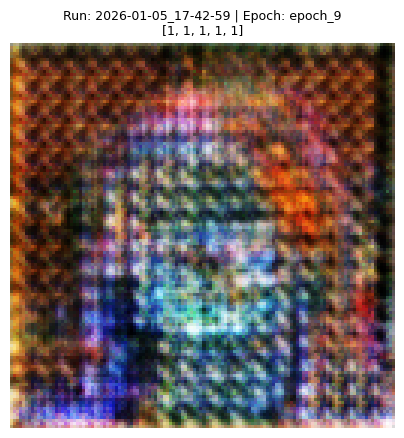

📁 Image sauvegardée dans : generated_results/2026-01-05_17-42-59/epoch_9/Male_1_Blond_Hair_1_Smiling_1_Eyeglasses_1_Young_1.png
👴 Utilisation de l'architecture V1 (Old 64x64)
Chargement : checkpoints/2026-01-05_17-42-59/netG_epoch_9.pth


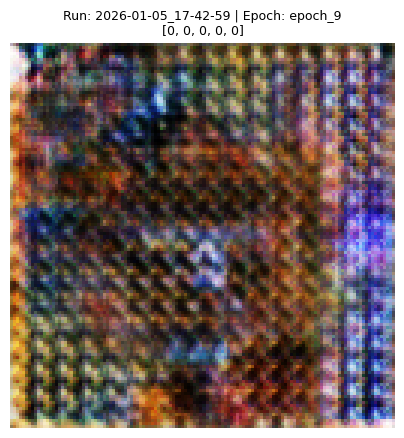

📁 Image sauvegardée dans : generated_results/2026-01-05_17-42-59/epoch_9/Male_0_Blond_Hair_0_Smiling_0_Eyeglasses_0_Young_0.png


In [86]:
# 1. Tu définis le dossier du run (regarde dans tes fichiers pour trouver le nom exact)
run_id = "2026-01-05_17-42-59"  # <--- À MODIFIER SELON TON RUN

# 2. Tu définis l'époque
epoch =9

# 3. Tu construis le chemin
path = os.path.join("checkpoints", run_id, f"netG_epoch_{epoch}.pth")

# 4. Tu génères
print(f"Test du modèle : {path}")

# Test Homme Blond Souriant
generate_specific_face({0: 1, 1: 1, 2: 1, 3: 1,4: 1}, model_path=path,force_old=True)

# Test Femme Brune Pas souriante
generate_specific_face({0: 0, 1: 0, 2: 0, 3: 0, 4: 0}, model_path=path,force_old=True)

In [ ]:
# --- CONFIGURATION DE REPRISE ---
RESUME_RUN_FOLDER = "2026-01-05_17-42-59" # <--- Mets le nom exact de ton dossier run actuel
LAST_COMPLETED_EPOCH = 49 # L'époque du dernier fichier .pth sauvegardé
ckpt_dir = os.path.join("checkpoints", RESUME_RUN_FOLDER)

print(f"🔄 Reprise de l'entraînement : {RESUME_RUN_FOLDER} à partir de l'époque {LAST_COMPLETED_EPOCH}")

# 1. Recharger les poids sauvegardés
path_G = os.path.join("checkpoints", RESUME_RUN_FOLDER, f"netG_epoch_{LAST_COMPLETED_EPOCH}.pth")
path_D = os.path.join("checkpoints", RESUME_RUN_FOLDER, f"netD_epoch_{LAST_COMPLETED_EPOCH}.pth")

netG.load_state_dict(torch.load(path_G, map_location=DEVICE))
netD.load_state_dict(torch.load(path_D, map_location=DEVICE))
print("✅ Poids rechargés avec succès.")

# 2. Configurer le Writer Tensorboard pour continuer sur la même courbe
# On pointe vers le MÊME dossier de logs
log_dir = os.path.join("logs", "cgan_celeba", RESUME_RUN_FOLDER)
writer = SummaryWriter(log_dir)

# 3. La boucle modifiée (Commence à LAST + 1)
START_EPOCH = LAST_COMPLETED_EPOCH + 1
global_step = LAST_COMPLETED_EPOCH * len(train_loader) // N_CRITIC  # Approximation
for epoch in range(START_EPOCH, NUM_EPOCHS):
    for i, (real_imgs, real_labels) in enumerate(train_loader):
        real_imgs = real_imgs.to(DEVICE)
        real_labels = real_labels.float().to(DEVICE)
        b_size = real_imgs.size(0)

        # ---------------------
        # 1. Train Discriminator
        # ---------------------
        optimizerD.zero_grad()
        
         # --- A. Real Images ---
        # D doit dire : Vrai (Score élevé) ET Bonnes Classes
        real_validity, real_cls_preds = netD(real_imgs)
        
        # WGAN Loss (On veut maximiser D(x) -> minimiser -D(x))
        d_loss_real = -torch.mean(real_validity)
        # Classif Loss
        d_loss_cls = cls_criterion(real_cls_preds, real_labels)

        # --- B. Fake Images ---
        # Génération
        z = torch.randn(b_size, Z_DIM, 1, 1).to(DEVICE)
        fake_labels = (torch.rand(b_size, NUM_CLASSES) > 0.5).float().to(DEVICE) # Random labels
        fake_imgs = netG(z, fake_labels)
        
        # D doit dire : Faux (Score faible)
        # On detach() car on n'entraîne pas G ici
        fake_validity, _ = netD(fake_imgs.detach())
        
        # WGAN Loss (On veut minimiser D(G(z)) -> maximiser D(G(z)) -> ajouter D(G(z)))
        d_loss_fake = torch.mean(fake_validity)
        
        # --- C. Gradient Penalty ---
        gradient_penalty = compute_gradient_penalty(netD, real_imgs.data, fake_imgs.data)
        
        # --- TOTAL D LOSS ---
        # WGAN : D(G(z)) - D(x) + GP
        d_loss = d_loss_fake + d_loss_real + (LAMBDA_GP * gradient_penalty) + (LAMBDA_CLS * d_loss_cls)
        
        d_loss.backward()
        optimizerD.step()

        # -----------------
        # 2. Train Generator
        #seulement une fois toutes les N_CRITIC itérations
        # -----------------
        if i % N_CRITIC == 0:
            optimizerG.zero_grad()
            # On ré-utilise les fake_imgs mais cette fois on garde le graph pour G
            # G veut tromper D : D doit dire "Vrai" et "Bonnes Classes"
            fake_validity, fake_cls_preds = netD(fake_imgs)
            
            # Adversarial Loss (WGAN) : Maximiser D(G(z)) -> Minimiser -D(G(z))
            g_loss_adv = -torch.mean(fake_validity)
            
            # Classification Loss : G doit générer des images qui correspondent aux fake_labels
            g_loss_cls = cls_criterion(fake_cls_preds, fake_labels)
            
            # TOTAL G LOSS
            g_loss = g_loss_adv + (LAMBDA_CLS * g_loss_cls)
            
            g_loss.backward()
            optimizerG.step()
            
            # --- Logging (Uniquement quand on update G) ---
            if global_step % 50 == 0:
                writer.add_scalar('Loss/D_Total', d_loss.item(), global_step)
                writer.add_scalar('Loss/G_Total', g_loss.item(), global_step)
                writer.add_scalar('Loss/W_Dist', -(d_loss_real + d_loss_fake).item(), global_step) # Wasserstein Distance estimate
                writer.add_scalar('Loss/Classif', d_loss_cls.item(), global_step)
                
            global_step += 1

        # Print périodique
        if i % 200 == 0:
             print(f"[Epoch {epoch}/{NUM_EPOCHS}] [Batch {i}/{len(train_loader)}] "
                   f"[D loss: {d_loss.item():.4f}] [G loss: {g_loss.item() if 'g_loss' in locals() else 0:.4f}]")
    lr_scheduler_G.step()
    lr_scheduler_D.step()
    
    # 1. Tensorboard Update
    with torch.no_grad():
        netG.eval() # Mode évaluation pour le générateur
        fake = netG(fixed_noise, fixed_labels).detach().cpu()
        grid = vutils.make_grid(fake, padding=2, normalize=True)
        writer.add_image('Images_Générées', grid, epoch)
        netG.train() # Repasser en mode entraînement

    
    # 2. SAUVEGARDE DES POIDS (CHECKPOINTS)
    # 2. Sauvegarde des Checkpoints dans le dossier du Run
    torch.save(netG.state_dict(), os.path.join(ckpt_dir, f'netG_epoch_{epoch}.pth'))
    torch.save(netD.state_dict(), os.path.join(ckpt_dir, f'netD_epoch_{epoch}.pth'))
    
    print(f"--> Epoch {epoch} terminée. Checkpoint sauvegardé dans {ckpt_dir}")

print("Entraînement terminé.")
writer.close()

In [73]:
#FID computation preparation

import torchvision.utils as vutils
from tqdm import tqdm

def prepare_fid_folders(netG, test_loader, run_name, epoch_num):
    """
    Prépare deux dossiers pour le calcul FID :
    - fid_outputs/real_images : Images du Test Set
    - fid_outputs/fake_images : Images générées par le modèle
    """
    
    # 1. Configuration des chemins
    base_dir = "fid_outputs"
    real_dir = os.path.join(base_dir, "fid_real")
    fake_dir = os.path.join(base_dir, f"fid_fake_{run_name}_ep{epoch_num}")
    
    os.makedirs(real_dir, exist_ok=True)
    os.makedirs(fake_dir, exist_ok=True)
    
    print(f"📂 Préparation des dossiers pour FID...")
    print(f"   Real: {real_dir}")
    print(f"   Fake: {fake_dir}")

    # 2. Sauvegarde des VRAIES images (Test Set)
    # On ne le fait qu'une fois, si le dossier est vide
    if len(os.listdir(real_dir)) < len(test_loader.dataset):
        print("   Sauvegarde des images réelles...")
        count_real = 0
        for i, (imgs, _) in enumerate(tqdm(test_loader)):
            for j in range(imgs.size(0)):
                # Dénormalisation (-1, 1) -> (0, 1) pour l'enregistrement PNG
                vutils.save_image(
                    imgs[j], 
                    os.path.join(real_dir, f"real_{count_real}.png"), 
                    normalize=True, value_range=(-1, 1)
                )
                count_real += 1
    else:
        print("   Images réelles déjà présentes.")

    # 3. Génération des FAUSSES images
    print("   Génération des images fausses...")
    netG.eval()
    count_fake = 0
    
    # On génère autant d'images qu'il y en a dans le test set
    total_images_to_gen = len(test_loader.dataset)
    
    with torch.no_grad():
        # On procède par batch pour aller vite
        while count_fake < total_images_to_gen:
            batch_size = BATCH_SIZE
            if count_fake + batch_size > total_images_to_gen:
                batch_size = total_images_to_gen - count_fake
            
            # Bruit aléatoire
            z = torch.randn(batch_size, Z_DIM, 1, 1).to(DEVICE)
            
            # Labels aléatoires (pour voir si le modèle gère tout)
            fake_labels = (torch.rand(batch_size, NUM_CLASSES) > 0.5).float().to(DEVICE)
            
            # Génération
            fake_imgs = netG(z, fake_labels)
            
            # Sauvegarde
            for j in range(fake_imgs.size(0)):
                vutils.save_image(
                    fake_imgs[j], 
                    os.path.join(fake_dir, f"fake_{count_fake}.png"), 
                    normalize=True, value_range=(-1, 1)
                )
                count_fake += 1
                
    print("✅ Dossiers prêts pour le calcul FID !")
    return real_dir, fake_dir

# --- LANCER LA PRÉPARATION ---
# Charge ton meilleur modèle avant !
epoch_to_test = 9 # Par exemple
path_to_model = os.path.join("checkpoints", RESUME_RUN_FOLDER, f"netG_epoch_{epoch_to_test}.pth")

# Chargement Poids
netG.load_state_dict(torch.load(path_to_model, map_location=DEVICE))

# Génération des dossiers
real_path, fake_path = prepare_fid_folders(netG, test_loader, RESUME_RUN_FOLDER, epoch_to_test)

/var/folders/qw/06dxj3m91kv23yphm00crzz00000gn/T/ipykernel_42624/857986422.py:84: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  netG.load_state_dict(torch.load(path_to_model

📂 Préparation des dossiers pour FID...
   Real: fid_outputs/fid_real
   Fake: fid_outputs/fid_fake_2026-01-06_16-32-52_V2_WGAN_ep9
   Images réelles déjà présentes.
   Génération des images fausses...
✅ Dossiers prêts pour le calcul FID !


In [74]:
print(f"Calcul du FID entre : \n{real_path} \net \n{fake_path}")
!python -m pytorch_fid "{real_path}" "{fake_path}" --device mps

Calcul du FID entre : 
fid_outputs/fid_real 
et 
fid_outputs/fid_fake_2026-01-06_16-32-52_V2_WGAN_ep9
100%|███████████████████████████████████████████| 40/40 [00:52<00:00,  1.32s/it]
FID:  158.41357295397606
